In [3]:
import pandas as pd
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [10]:
BRIDGE = "data/bridge_matrices.xlsx"
IMPACTS = "data/bubble_data_by_indicator_2015.xlsx"
FOOTPRINT = "M_imp*Y_dom+M_dom*Y_dom+M_row*Y_imp"
ID_COLS = ["category", "sub_category", "sector"]

Import des catégories des secteurs

In [11]:
def load_categories(path=BRIDGE, sheet="M_analyse"):
    raw = pd.read_excel(path, sheet_name=sheet, header=None)
    attributes = [str(v).strip() for v in raw.iloc[0, 3:]]     # Food, Cereals, ... (ligne 0)
    df = raw.iloc[2:].reset_index(drop=True)              # ligne 1 = en-têtes category/sub_category/sector
    df.columns = ID_COLS + attributes
    for c in ID_COLS:
        df[c] = df[c].astype(str).str.strip()
    df[attributes] = df[attributes].apply(pd.to_numeric).fillna(0).astype(int)  # 0/1 : appartenance à l'attribut
    return df, attributes

In [12]:
m, attributes = load_categories()
m.to_pickle("pkl/Categories.pkl") 

Import des impacts par secteur

In [13]:
def load_impacts(sheet, path=IMPACTS, row=FOOTPRINT):
    raw = pd.read_excel(path, sheet_name=sheet, header=None)
    start = raw.index[raw[0].astype(str).str.startswith("Source data")][0] + 1
    block = raw.iloc[start:].set_index(0)
    block.columns = [str(c).strip() for c in block.iloc[0]]
    block = block.iloc[1:]
    
    block = block.apply(pd.to_numeric, errors="coerce")
    block = block.dropna(how="all")
    
    block.index.name = sheet
    return block

In [ ]:
hanpp = load_impacts("Biodiversity loss - HANPP")
d = m.merge(hanpp.rename("impact"), left_on="sector", right_index=True, how="left")
d.to_pickle("pkl/hanpp.pkl")


Secteurs sans valeur : ['Rubber and plastic products (25)', 'Private households with employed persons (95)']


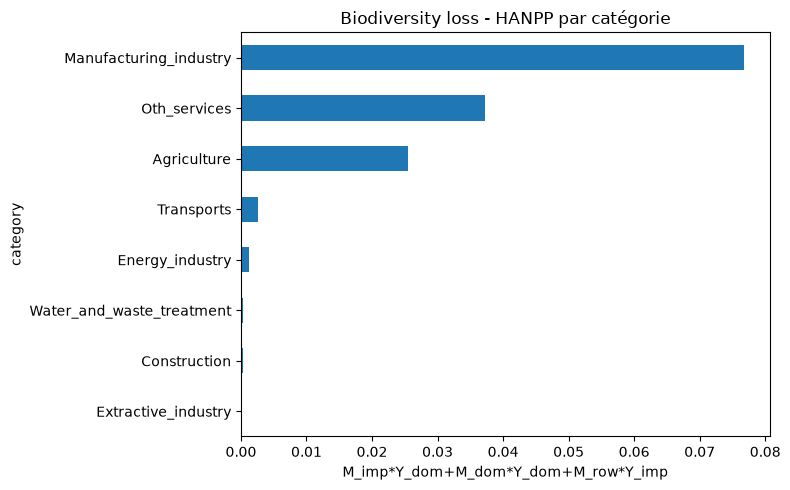

In [22]:
d.groupby("category")["impact"].sum().sort_values().plot.barh(figsize=(8, 5))
plt.xlabel(FOOTPRINT); plt.title("Biodiversity loss - HANPP par catégorie"); plt.tight_layout(); plt.show()